# Assignment 1 – Supervised Learning
## Part 1 – Logistic Regression

## Import Libraries

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Load and check Dataset

In [53]:
df = pd.read_csv('diabetes.csv')
display(df.head())
print(f'df.shape: {df.shape}')

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


df.shape: (768, 9)


## Describe Variables


| Variable | Short description |
|---|---|
| `Pregnancies` | Number of pregnancies. |
| `Glucose` | Concentration of glucose. |
| `BloodPressure` | Blood pressure of the patient. |
| `SkinThickness` | Skin thickness. |
| `Insulin` | Insulin level. |
| `BMI` | Body Mass Index. |
| `DiabetesPedigreeFunction` | Score that represents the family history of diabetes. |
| `Age` | Age in years. |
| `Outcome` | 0 indicates no diabetes and 1 indicates diabetes. |

In [54]:
display(df.describe())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## Plot Variables

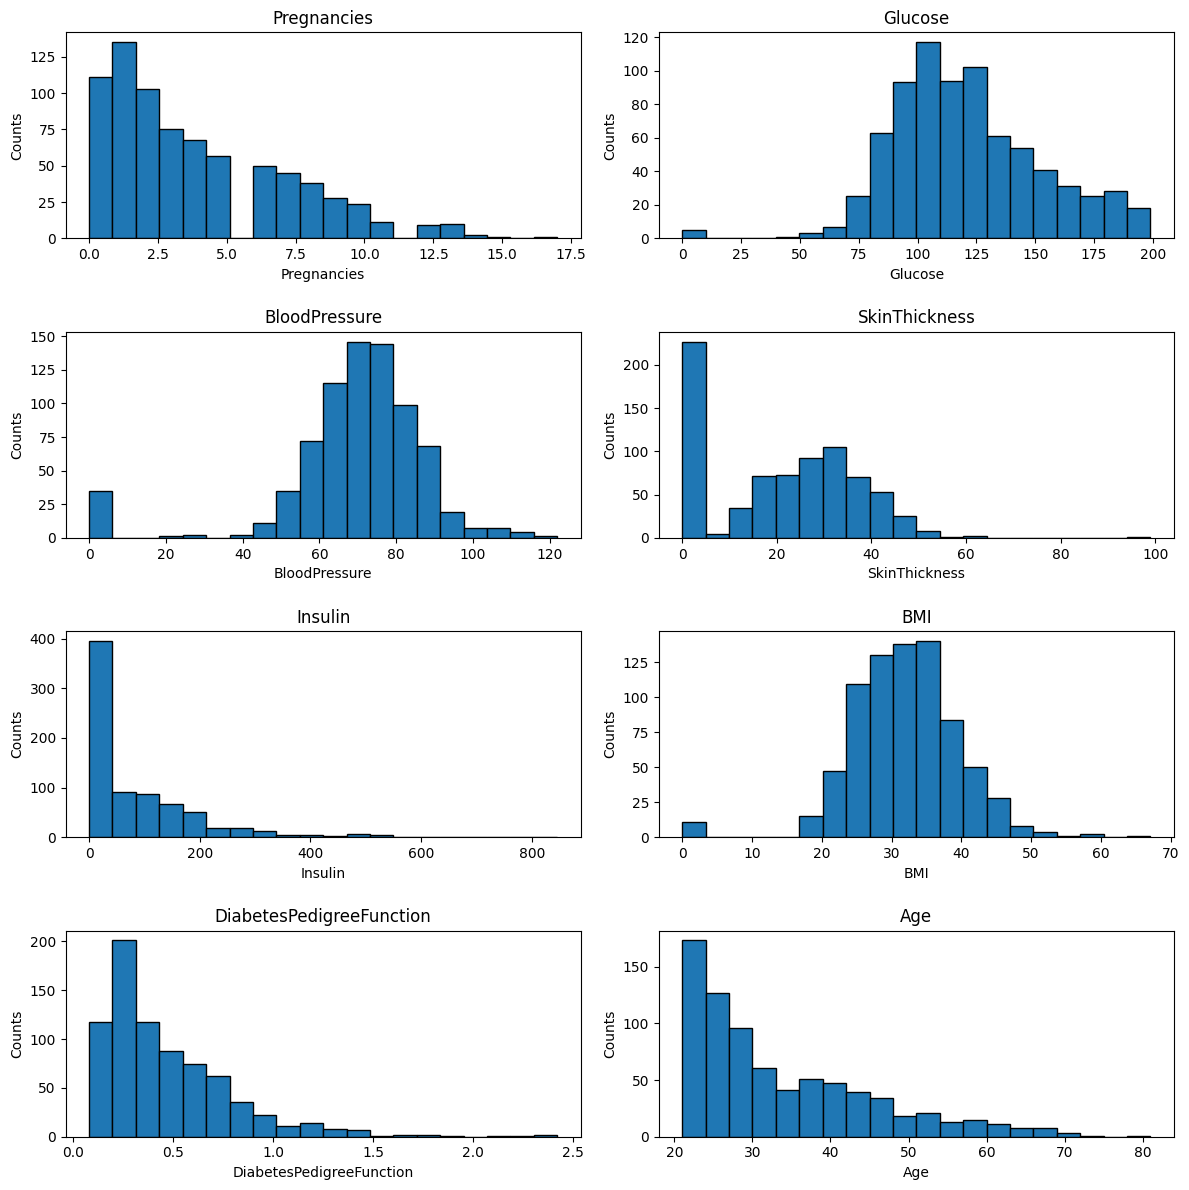

In [55]:

hvars = df.drop(columns=['Outcome'])
fig, axes = plt.subplots(4, 2, figsize=(12, 12))
axes = axes.flatten()

for i, col in enumerate(hvars):
  axes[i].hist(hvars[col], bins=20, edgecolor="black")
  axes[i].set_title(col)
  axes[i].set_xlabel(col)
  axes[i].set_ylabel("Counts")

plt.tight_layout(h_pad=2)
plt.show()

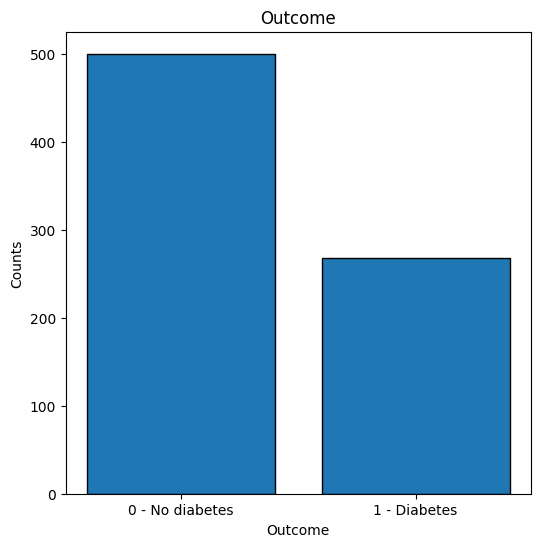

In [56]:
counts = df['Outcome'].value_counts()

plt.figure(figsize=(6,6))
plt.title('Outcome')
plt.xlabel('Outcome')
plt.ylabel('Counts')
plt.grid(False)
plt.xticks([0, 1], ['0 - No diabetes', '1 - Diabetes'])
plt.bar(counts.index, counts.values, edgecolor='black')

plt.show()

# 2. Convert DataFrame to Numpy arrays

In [33]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()

print(f'x.shape: {x.shape}')
print(f'y.shape: {y.shape}')


x.shape: (768, 8)
y.shape: (768,)


## Split Dataset to Train-Test

Train Samples: 537
Test Samples: 231
Seed: 0

Seed enables reproducibility

In [34]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)

print(f'x_train.shape: {x_train.shape}')
print(f'y_train.shape: {y_train.shape}')
print(f'x_test.shape: {x_test.shape}')
print(f'y_test.shape: {y_test.shape}')

x_train.shape: (537, 8)
y_train.shape: (537,)
x_test.shape: (231, 8)
y_test.shape: (231,)


# 3. Create and train a Logistic Regression Model

In [35]:
model = LogisticRegression(max_iter=5000, random_state=seed)
model.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=0)

## Evaluate Model on test set

In [36]:
y_pred = model.predict(x_test)
y_pred



array([1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0])

In [37]:
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}')

The accuracy of the model is: 77.92


## Evaluate Model on train set

In [38]:
y_train_pred = model.predict(x_train)
y_train_pred

array([1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,

In [39]:
train_accuracy = accuracy_score(y_train, y_train_pred)
train_accuracy_percentage = round(train_accuracy*100, 2)

print(f'The train accuracy of the model is: {train_accuracy_percentage}')

The train accuracy of the model is: 76.54


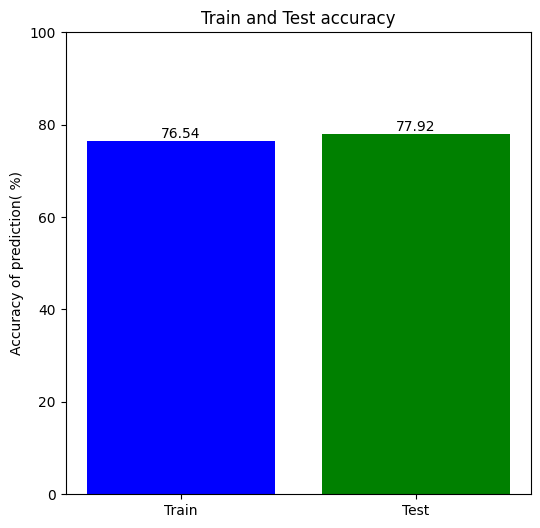

In [40]:
labels = ['Train', 'Test']
accuracies = [train_accuracy_percentage, accuracy_percentage]

plt.figure(figsize=(6,6))
bars = plt.bar(labels, accuracies, color=['blue', 'green'])

plt.bar_label(bars)
plt.title('Train and Test accuracy')
plt.ylabel('Accuracy of prediction( %)')
plt.ylim(0, 100)
plt.show()

The model appears to behave slightly better in the test set.

The difference is small (1.38) enough that it cannot give any strong indication of overfitting.

# 4. Glucose - Outcome relationship

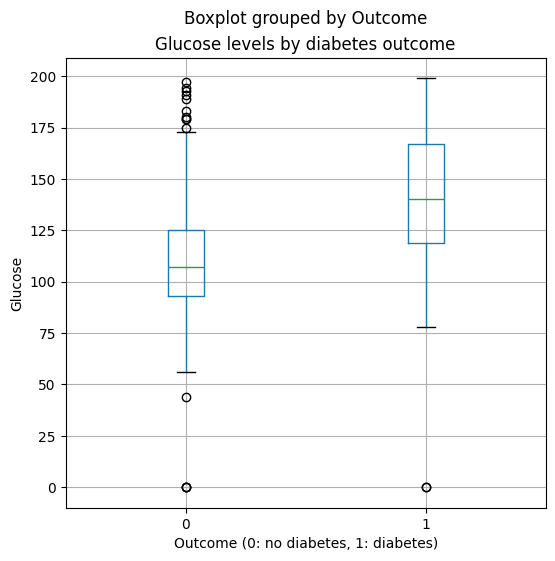

In [41]:
plt.figure(figsize=(6,6))
df.boxplot(column='Glucose', by='Outcome', ax=plt.gca())

plt.title('Glucose levels by diabetes outcome')
plt.xlabel('Outcome (0: no diabetes, 1: diabetes)')
plt.ylabel('Glucose')

plt.show()

### Results

There is an overlap of patients in the range of glucose around 125 and some outliers which may lead to inconclusive results but in general we can say that patients with higher glucose tend to also be diabetics.

# 5. Age Groups Test

In [42]:
age_test = x_test[:, 7]
age_groups = {
    '0 to 25': age_test <= 25,
    '26 to 50': (age_test > 25) & (age_test <= 50),
    '50+': age_test > 50
}

accuracies = []
for group, mask in age_groups.items():
  accuracy = accuracy_score(y_test[mask], y_pred[mask]) * 100
  accuracies.append(accuracy)
  print(f'{group}: {accuracy} ({mask.sum()} patients)')

0 to 25: 85.55555555555556 (90 patients)
26 to 50: 70.0 (120 patients)
50+: 90.47619047619048 (21 patients)


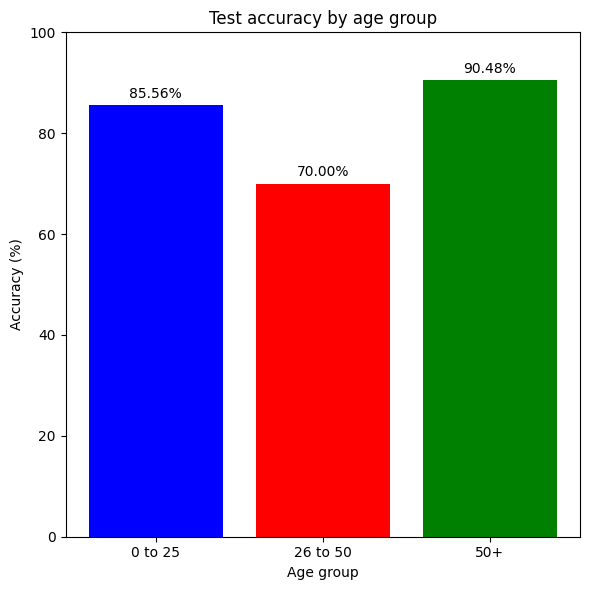

In [43]:
plt.figure(figsize=(6,6))

bars = plt.bar(
    list(age_groups.keys()),
    accuracies,
    color=['blue', 'red', 'green']
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title('Test accuracy by age group')
plt.xlabel('Age group')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

It seems that our model is not performing equally well across all the age groups. We have the best performance in the groups <= 25 with 85.56% and 50+ with 90.48%.

While the last group has the highest accuracy  it only contains 21 patients and the lowest performing group contains most patients (120).

# 6. False results

Predicting a false negative is worse than predicting a false positive in general. A patient who is not diabetic that gets a false positive will go through the self checkup procedure and confirm/clarify the results. A patient that is a false negative may not do follow-up tests until he has serious implications.

---

## Part 2 – Linear Regression



In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

# 1. Load and check Dataset

In [45]:
df = pd.read_csv('diabetes.csv')
display(df.head())
print(f'df.shape: {df.shape}')

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


df.shape: (768, 9)


In [46]:
input_df = df[['Pregnancies', 'BloodPressure', 'BMI', 'Age']]
targets_df = df['Glucose']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

print(f'x.shape: {x.shape}')
print(f'y.shape: {y.shape}')


x.shape: (768, 4)
y.shape: (768,)


In [47]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)

print(f'x_train.shape: {x_train.shape}')
print(f'y_train.shape: {y_train.shape}')
print(f'x_test.shape: {x_test.shape}')
print(f'y_test.shape: {y_test.shape}')

x_train.shape: (537, 4)
y_train.shape: (537,)
x_test.shape: (231, 4)
y_test.shape: (231,)


# 2. Create and train a Linear Regression Model



In [48]:
model = LinearRegression().fit(x_train, y_train)

y_pred = model.predict(x_test)
y_train_pred = model.predict(x_train)


## Calculate metrics



In [49]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f'MAE: {mae:.2f}')
print(f'MSE: {mse:.2f}')

MAE: 23.60
MSE: 929.89


MSE should be more appropriate to use in this case because it penalizes large prediction errors stronger than MAE.

# 3. Feature Importance

Retrain the model using standard scaling. Then, investigate coefficients. Larger coefficient values $\rightarrow$ more important features

## Data Normalization

In [50]:
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


In [51]:
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
scaled_mae = mean_absolute_error(y_test, y_pred)
scaled_mse = mean_squared_error(y_test, y_pred)

print(f'MAE after scaling: {scaled_mae:.2f}')
print(f'MSE after scaling: {scaled_mse:.2f}')


MAE after scaling: 23.60
MSE after scaling: 929.89


[-0.5721754   0.79361638  7.56207971  9.21462731]


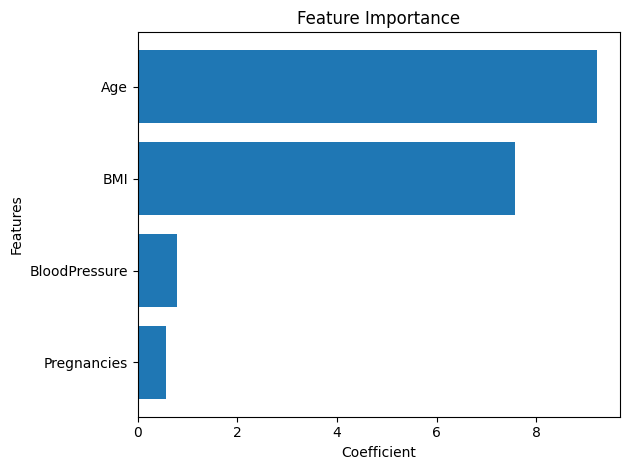

In [52]:
coeffs = model.coef_
importance_weights = np.abs(coeffs)

print(coeffs)

plt.barh(input_df.columns, importance_weights)
plt.title('Feature Importance')
plt.xlabel('Coefficient')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


The most important feature for glucose prediction appears to be the Age of the patient. BMI is also important compared to BloodPressure and Pregnancies.